# Stage 03 — Stopwords and Morphology

## Objective

Measure two controlled preprocessing ablations for the E-commerce classification task:
**A:** no stopword removal versus NLTK English stopwords, using vocabulary, document-presence
Mutual Information (MI) and Multinomial Naive Bayes; **B:** no morphology versus Porter,
Snowball and noun-default WordNet, using type collisions and Logistic Regression five-fold CV.
The [assignment](https://hcmus-cs-ta.github.io/lab-book/data-mining/projects/preprocessing/)
requires these comparisons and a critical explanation of their effects.

Re-read the original [Kaggle CSV](https://www.kaggle.com/datasets/saurabhshahane/ecommerce-text-classification)
and recreate [Stage 02](02_normalization_tokenization.ipynb)'s fixed protocol. All descriptive
metrics and CV use **TRAIN only**. The internal-assessment partition is reconstructed solely
to verify membership separation/fingerprints; its text is not normalized, tokenized, scored
or used to choose a policy. Stage 01 already exposed the full corpus, so it is an internal
post-EDA assessment, not a new external test. Representation benchmarks remain Stage 04 work;
Count and TF-IDF here serve only the required ablations.

## Methodology

**One base input.** Reuse the unchanged Stage 02 default normalization: NFKC, lowercase,
recognized tags/entities, URL/mention handling, hashtag marker removal, conditional symbols,
**retain numbers**, then whitespace. Tokenize with the same lowercase lexical regex
`[^\W_]+(?:['’][^\W_]+)*`. This is Stage 02's lexical diagnostic, not its separate Treebank
benchmark input. Hyphens/dots delimit lexical pieces; digit-bearing pieces remain present.
The baseline's removal of `@home` is a known brand-information risk, not silently repaired here.
Raw strings and source row IDs remain intact.

**Freeze CV before ablation.** Audit equal normalized base strings on TRAIN. If duplicates
exist, use five `StratifiedGroupKFold` folds grouped by that base text, `shuffle=True`, seed 42;
otherwise use fixed `StratifiedKFold`. Stopword removal and morphology never redefine groups.
Keep all rows, including empty token lists. All fitted vocabularies, IDF and classifiers are
learned inside each fold's fitting partition. Fixed stopwords and pretrained dictionaries/
stateless stemmers may be applied in advance; they do not estimate parameters from validation.
Type-map memoization is only a cache of stateless outputs, not a model feature vocabulary.

**Stopword metrics.** Match complete lowercase lexical tokens against the fixed NLTK English
list. Type-removal percentage divides by original training types; occurrence-removal percentage
divides by original training token occurrences. Length summaries use token-list lengths and
retain empty lists. No domain stopwords or morphology are added to this ablation.

**Document-presence MI**, natural logarithms (nats):

$$
I(X_w;Y)=\sum_{x\in\{0,1\}}\sum_{y=1}^{4}
\hat p(x,y)\log\frac{\hat p(x,y)}{\hat p(x)\hat p(y)},\qquad 0\log 0=0.
$$

Use an empirical 2×4 contingency table per word, from binary sparse document features,
`min_df=1`, with both presence and absence counts. This is a descriptive plug-in estimate on
TRAIN, not continuous term-frequency MI, a significance test or feature selection for CV.
Wordwise means depend on the vocabulary averaged over; their sum is not joint information
because word events are dependent. Common-word MI must remain unchanged when only other words
are deleted and the document population stays fixed.

**Morphology metrics.** For unique input types $V$, map each type to one form, yielding $U$
unique forms. Report distinct definitions:

$$
\mathrm{compression}=\frac{V-U}{V},\qquad
\mathrm{collision\ membership}=\frac{\sum_{g:|g|\ge2}|g|}{V}.
$$

The second counts input types belonging to multi-input groups, not lost types or token
occurrences. All lexical types are the denominator, including unchanged numbers/codes;
also report eligible ASCII alphabetic types. Keep stopwords in all four morphology variants.

**CV estimands.** Report five macro-F1 scores, arithmetic mean, sample SD (`ddof=1`), accuracy
and fold vocabulary sizes. Reuse the same folds for every method. Paired fold differences help
describe magnitude; folds share training data, so SD is neither a confidence interval nor a
proof of improvement. No hyperparameter search or internal-assessment selection is performed.

## Implementation

Use the existing `.venv` and `hcmus-wids` kernel from repository root or `book/text/`. Shared
pure normalization functions now live in `src/text_preprocessing.py`; Stage 02 imports them
with identical behavior. This notebook imports no notebook and needs no processed cache.
Only NLTK **stopwords** and **wordnet** are added to the local resource cache, with guarded
lookup/download and actionable errors. No POS tagger, OMW, new package, GPU framework or
representation library is needed. Static HTML uses the saved outputs without CSV/resources.

In [1]:
from pathlib import Path
from collections import Counter, defaultdict
from importlib.metadata import version
from time import perf_counter
import hashlib
import html
import os
import platform
import re
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse
import nltk
from nltk.corpus import stopwords, wordnet
from nltk.stem import PorterStemmer, SnowballStemmer, WordNetLemmatizer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.metrics import f1_score, accuracy_score
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits
from IPython.display import display, HTML

ROOT=next((p for p in (Path.cwd(),*Path.cwd().parents)
           if (p/"myst.yml").is_file() and (p/"src/text_data.py").is_file()),None)
if ROOT is None: raise RuntimeError("Start inside this repository.")
if Path(sys.prefix).resolve()!=(ROOT/".venv").resolve():
    raise RuntimeError("Select the existing .venv kernel (hcmus-wids), restart and Run All.")
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from src.text_data import LABELS, read_ecommerce, make_text_protocol
from src.text_preprocessing import normalize_default, lexical_tokens
DATA_PATH=ROOT/"data/raw/ecommerce/ecommerceDataset.csv"
SEED=42
sns.set_theme(style="whitegrid",context="notebook")
plt.rcParams.update({"figure.dpi":110,"savefig.dpi":140})

def prose(text):
    safe=html.escape(text)
    return HTML("<p>"+re.sub(r"\*\*(.+?)\*\*",r"<strong>\1</strong>",safe)+"</p>")

def show_table(frame,title=None,collapse=False,**kwargs):
    body='<div style="overflow-x:auto">'+frame.to_html(escape=True,**kwargs)+'</div>'
    if collapse: body=f"<details><summary>{html.escape(title or 'Supporting table')}</summary>{body}</details>"
    elif title: body=f"<p><strong>{html.escape(title)}</strong></p>"+body
    display(HTML(body))

print("Python",platform.python_version(),"|",platform.system(),platform.machine(),"| logical CPUs",os.cpu_count())
show_table(pd.DataFrame({"package":["pandas","scipy","scikit-learn","nltk"],
                         "version":[version(p) for p in ["pandas","scipy","scikit-learn","nltk"]]}),index=False)

Python 3.13.3 | Darwin arm64 | logical CPUs 8


package,version
pandas,3.1.0
scipy,1.18.1
scikit-learn,1.9.1
nltk,3.10.4


In [2]:
NLTK_DIR=ROOT/".cache/nltk_data"
nltk.data.path.insert(0,str(NLTK_DIR))
resource_preparation=[]
for package,probes in [("stopwords",["corpora/stopwords/"]),
                       ("wordnet",["corpora/wordnet/","corpora/wordnet.zip"])]:
    available=False
    for probe in probes:
        try: nltk.data.find(probe);available=True;break
        except LookupError: pass
    if not available:
        try:
            nltk.download(package,download_dir=str(NLTK_DIR),quiet=True,raise_on_error=True)
        except Exception:
            raise RuntimeError(f"Missing NLTK {package}. With .venv active, run: "
                               f"python -m nltk.downloader -d .cache/nltk_data {package}; then rerun. "
                               "No fallback resource is substituted.") from None
    resource_preparation.append({"resource":package,"status":"reused" if available else "downloaded once"})
english_stopwords=frozenset(stopwords.words("english"))
wordnet_version=wordnet.get_version()
resource_fingerprints={}
with stopwords.open("english") as file:
    resource_fingerprints["stopwords/english"]=hashlib.sha256(file.read().encode()).hexdigest()
for name in ["index.noun","data.noun","noun.exc"]:
    with wordnet.open(name) as file:
        resource_fingerprints["wordnet/"+name]=hashlib.sha256(file.read().encode()).hexdigest()
show_table(pd.DataFrame(resource_preparation),index=False)
print("NLTK English stopwords:",len(english_stopwords),"| WordNet version:",wordnet_version)
show_table(pd.Series(resource_fingerprints,name="SHA-256").to_frame(),"Resource provenance",collapse=True)

resource,status
stopwords,reused
wordnet,reused


NLTK English stopwords: 198 | WordNet version: 3.0


,SHA-256
stopwords/english,f6d005956f407dbc6ea32e5ff0c7e8e6f71488d3239b9023efdc7fc139d6375b
wordnet/index.noun,a490d99d93d017bf4822fe2f0ffa51fd73911ce271dc7535fade21f8814b5a04
wordnet/data.noun,489f145e0f68877c0be5bd0eb4117adaaac52f38f6204eb8d85dbe2158b614cc
wordnet/noun.exc,2b5d675c380b39ecf595af9fa9d4e7feb1d58c643b0bff08c40ed5bfe41fab7a


### Small analysis and fold-fitting functions

MI aggregates only a 4×V count array from the sparse matrix, never a dense N×V document matrix.
The collision helper operates on a mapping of **unique types**. The fold helper constructs a
new vectorizer/classifier pipeline on each call and fits only the supplied fitting indices.
All captured warnings are recorded and re-emitted, including convergence warnings; none is
silently suppressed.

In [3]:
def remove_stopwords(tokens,stop_set):
    return [token for token in tokens if token not in stop_set]

def binary_word_mi(matrix,labels):
    if not sparse.issparse(matrix): raise TypeError("Use a sparse binary document matrix")
    matrix=matrix.tocsr()
    labels=np.asarray(labels)
    if matrix.shape[0]!=len(labels): raise ValueError("Row/label mismatch")
    if not np.isin(matrix.data,[0,1]).all(): raise ValueError("MI input must be binary presence")
    classes,encoded=np.unique(labels,return_inverse=True)
    class_N=np.bincount(encoded,minlength=len(classes)).astype(np.float64)
    present=np.vstack([np.asarray(matrix[encoded==k].sum(axis=0)).ravel() for k in range(len(classes))])
    N=len(labels);mi=np.zeros(matrix.shape[1],dtype=np.float64)
    for joint in [present,class_N[:,None]-present]:
        state_N=joint.sum(axis=0)
        expected=class_N[:,None]*state_N[None,:]/N
        ratio=np.ones_like(joint,dtype=np.float64)
        np.divide(joint,expected,out=ratio,where=joint>0)
        mi+=(joint/N*np.log(ratio)).sum(axis=0)
    return mi

def collision_summary(mapping):
    groups=defaultdict(list)
    for token,form in mapping.items(): groups[form].append(token)
    V,U=len(mapping),len(groups)
    colliding_types=sum(len(words) for words in groups.values() if len(words)>=2)
    return {"V_input_types":V,"U_output_forms":U,"compression_pct":100*(V-U)/V,
            "types_in_collision_groups":colliding_types,"collision_membership_pct":100*colliding_types/V,
            "multi_input_groups":sum(len(words)>=2 for words in groups.values()),
            "changed_types":sum(token!=form for token,form in mapping.items())},dict(groups)

def identity_tokens(tokens): return tokens

def make_model_pipeline(family):
    if family=="NB":
        vectorizer=CountVectorizer(analyzer=identity_tokens,min_df=1,max_df=1.0,max_features=None,
                                   binary=False,dtype=np.int64)
        estimator=MultinomialNB(alpha=1.0,fit_prior=True,force_alpha=True)
    elif family=="LR":
        vectorizer=TfidfVectorizer(analyzer=identity_tokens,min_df=2,max_df=1.0,max_features=30000,
                                   ngram_range=(1,1),norm="l2",use_idf=True,smooth_idf=True,
                                   sublinear_tf=True,dtype=np.float64)
        # l1_ratio=0 selects L2 in the pinned sklearn API; no deprecated penalty override.
        estimator=LogisticRegression(C=1.0,l1_ratio=0.0,solver="lbfgs",max_iter=1000,
                                     tol=1e-4,random_state=42)
    else: raise ValueError("family must be NB or LR")
    return Pipeline([("vectorizer",vectorizer),("classifier",estimator)])

def score_fold(documents,labels,fitting,validation,*,family):
    documents=pd.Series(documents).reset_index(drop=True)
    labels=np.asarray(labels)
    pipeline=make_model_pipeline(family)
    started=perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        pipeline.fit(documents.iloc[fitting].tolist(),labels[fitting])
        predictions=pipeline.predict(documents.iloc[validation].tolist())
    warning_rows=[{"category":w.category.__name__,"message":str(w.message)} for w in caught]
    for w in caught: warnings.warn(str(w.message),w.category,stacklevel=2)
    classifier=pipeline.named_steps["classifier"]
    record={"macro_F1":f1_score(labels[validation],predictions,average="macro",zero_division=0),
            "accuracy":accuracy_score(labels[validation],predictions),
            "vocabulary":len(pipeline.named_steps["vectorizer"].vocabulary_),
            "seconds":perf_counter()-started,"warnings":len(caught),
            "convergence_warnings":sum(issubclass(w.category,ConvergenceWarning) for w in caught),
            "iterations":int(np.max(classifier.n_iter_)) if family=="LR" else None}
    return record,pipeline,warning_rows

## Results

### Raw protocol, Stage 02 fingerprint check and base TRAIN input

Source SHA-256 and partition fingerprints below are **references recorded by Stage 02**,
compared with values recomputed from raw here. They are not substituted sample counts.
A mismatch must be resolved before claiming that the chapters share a protocol. The raw
frame is snapshotted for a final read-only check. The assessment contributes only its row
IDs and canonical keys to separation checks; all following text analysis uses TRAIN.

In [4]:
if not DATA_PATH.is_file():
    raise FileNotFoundError("Place the original Kaggle ecommerceDataset.csv in data/raw/ecommerce/; see README.")
raw_sha256_before=hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
raw=read_ecommerce(DATA_PATH);raw_snapshot=raw.copy(deep=True)
protocol=make_text_protocol(raw,test_size=.2,seed=SEED)
train=protocol["train"].copy()
assessment_ids=protocol["test"].row_id.copy()
observed_fingerprints={"source":raw_sha256_before,
    "train":hashlib.sha256(train.row_id.to_numpy(dtype="<i8").tobytes()).hexdigest(),
    "assessment":hashlib.sha256(assessment_ids.to_numpy(dtype="<i8").tobytes()).hexdigest()}
STAGE02_REFERENCES={"source":"1d44be1780bc9558f40ab4cee5b32051ddfe90647cd525b9652b47cdb233593f",
    "train":"b36f8f64739c881a5beb35e57b0a5068f3a319733506aca0b34a89ccdac0fe2c",
    "assessment":"737d4fab65e776bce15718b1e512546b547a6bc53802d7f3228933293084cce6"}
fingerprint_table=pd.DataFrame({"observed":observed_fingerprints,"Stage02_reference":STAGE02_REFERENCES})
fingerprint_table["matches"]=fingerprint_table.observed.eq(fingerprint_table.Stage02_reference)
show_table(fingerprint_table[["matches"]],"Source and partition checks against Stage 02")
show_table(fingerprint_table,"Recomputed source and partition fingerprints",collapse=True)
assert fingerprint_table.matches.all(),"Source/protocol differs from Stage 02; investigate rather than force counts."
assert set(train.row_id).isdisjoint(assessment_ids)
assert set(train.canonical_key).isdisjoint(protocol["test"].canonical_key)
show_table(protocol["flow"],"Raw-to-corpus flow recreated by the unchanged helper",index=False)
train_support=train.label.value_counts().reindex(LABELS).rename("train_N").to_frame()
train_support["train_pct"]=100*train_support.train_N/len(train)
show_table(train_support.round(3))
print("Recomputed TRAIN / internal-assessment N:",len(train),"/",len(assessment_ids))

base_text=train.text.map(normalize_default)
base_tokens=base_text.map(lexical_tokens)
y=train.label.to_numpy()
base_counter=Counter(token for tokens in base_tokens for token in tokens)
base_vocabulary=sorted(base_counter)
base_lengths=base_tokens.map(len)
show_table(pd.Series({"training_rows":len(train),"base_types":len(base_counter),
    "base_token_occurrences":sum(base_counter.values()),"mean_tokens":base_lengths.mean(),
    "median_tokens":base_lengths.median(),"P95_tokens":base_lengths.quantile(.95),
    "empty_base_token_lists":int(base_lengths.eq(0).sum())},name="TRAIN base",dtype="object").to_frame())
assert len(base_tokens)==len(train) and base_text.notna().all()
display(prose(f"**Observed:** the source/fingerprints match Stage 02; TRAIN contains **{len(train):,}** rows, "
              f"assessment **{len(assessment_ids):,}**. All ablations share **{len(base_counter):,}** base lexical "
              f"types and **{sum(base_counter.values()):,}** token occurrences. "
              "Only the training text enters the following statistics and CV."))

,matches
source,True
train,True
assessment,True


,observed,Stage02_reference,matches
source,1d44be1780bc9558f40ab4cee5b32051ddfe90647cd525b9652b47cdb233593f,1d44be1780bc9558f40ab4cee5b32051ddfe90647cd525b9652b47cdb233593f,True
train,b36f8f64739c881a5beb35e57b0a5068f3a319733506aca0b34a89ccdac0fe2c,b36f8f64739c881a5beb35e57b0a5068f3a319733506aca0b34a89ccdac0fe2c,True
assessment,737d4fab65e776bce15718b1e512546b547a6bc53802d7f3228933293084cce6,737d4fab65e776bce15718b1e512546b547a6bc53802d7f3228933293084cce6,True


step,removed_rows,remaining_rows
raw CSV,0,50425
missing / blank text,1,50424
missing / invalid label,0,50424
all conflicting-label canonical groups,0,50424
exact duplicate rows after first,22622,27802
additional canonical duplicates after first,50,27752


,train_N,train_pct
label,,
Household,8449,38.057
Books,4976,22.413
Clothing & Accessories,4533,20.418
Electronics,4243,19.112


Recomputed TRAIN / internal-assessment N: 22201 / 5551


,TRAIN base
training_rows,22201
base_types,72299
base_token_occurrences,2548397
mean_tokens,114.787487
median_tokens,78.0
P95_tokens,312.0
empty_base_token_lists,0


### Frozen grouped five-fold CV

Groups are equal normalized **base text strings**, before stopword removal or morphology.
An audit also reports groups with multiple labels; grouping keeps such rows together without
relabeling or deleting them. Related product variants and different normalized strings with
similar meaning are not fully addressed. This extra within-TRAIN grouping does not change
Stage 02's outer membership or claim to make the outer assessment family independent.

In [5]:
normalized_groups=train.assign(base=base_text).groupby("base",sort=False).agg(
    rows=("row_id","size"),labels=("label","nunique"))
group_audit=pd.Series({"unique_base_text_groups":len(normalized_groups),
    "duplicate_groups":int(normalized_groups.rows.ge(2).sum()),
    "redundant_rows":int((normalized_groups.rows-1).sum()),
    "rows_in_duplicate_groups":int(normalized_groups.loc[normalized_groups.rows.ge(2),"rows"].sum()),
    "conflicting_label_groups":int(normalized_groups.labels.gt(1).sum())},name="TRAIN normalized audit")
show_table(group_audit.to_frame())
group_ids=pd.factorize(base_text,sort=True)[0]
if normalized_groups.rows.ge(2).any():
    splitter=StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=SEED)
    folds=list(splitter.split(np.zeros(len(train)),y,groups=group_ids))
else:
    splitter=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
    folds=list(splitter.split(np.zeros(len(train)),y))
fold_rows=[];support_rows=[];validation_use=np.zeros(len(train),dtype=int)
for fold,(fitting,validation) in enumerate(folds,1):
    overlap=len(set(group_ids[fitting])&set(group_ids[validation]))
    assert overlap==0 and set(fitting).isdisjoint(validation)
    assert set(y[fitting])==set(LABELS) and set(y[validation])==set(LABELS)
    validation_use[validation]+=1
    fold_rows.append({"fold":fold,"fit_N":len(fitting),"validation_N":len(validation),
        "group_overlap":overlap,
        "validation_row_ID_SHA256":hashlib.sha256(np.sort(train.iloc[validation].row_id.to_numpy(dtype="<i8")).tobytes()).hexdigest()})
    for label in LABELS:
        support_rows.append({"fold":fold,"label":label,"fit_N":int((y[fitting]==label).sum()),
                             "validation_N":int((y[validation]==label).sum()),
                             "validation_pct":100*(y[validation]==label).mean()})
assert np.all(validation_use==1)
fold_table=pd.DataFrame(fold_rows)
show_table(fold_table.drop(columns="validation_row_ID_SHA256"),"Fixed folds reused by all six configurations",index=False)
show_table(pd.DataFrame(support_rows).round(3),"All per-class fold supports",collapse=True,index=False)
show_table(fold_table[["fold","validation_row_ID_SHA256"]],"Fold membership fingerprints",collapse=True,index=False)
display(prose(f"**Observed:** {int(group_audit.duplicate_groups)} normalized duplicate groups contain "
              f"{int(group_audit.redundant_rows)} redundant rows; use **{type(splitter).__name__}**. "
              "Every record is validated exactly once, all four labels occur in every fitting/validation "
              "partition, and normalized-group overlap is zero in all five folds."))

,TRAIN normalized audit
unique_base_text_groups,22189
duplicate_groups,11
redundant_rows,12
rows_in_duplicate_groups,23
conflicting_label_groups,0


fold,fit_N,validation_N,group_overlap
1,17760,4441,0
2,17761,4440,0
3,17761,4440,0
4,17761,4440,0
5,17761,4440,0


fold,label,fit_N,validation_N,validation_pct
1,Household,6759,1690,38.054
1,Books,3981,995,22.405
1,Clothing & Accessories,3626,907,20.423
1,Electronics,3394,849,19.117
2,Household,6759,1690,38.063
2,Books,3981,995,22.410
2,Clothing & Accessories,3626,907,20.428
2,Electronics,3395,848,19.099
3,Household,6760,1689,38.041
3,Books,3981,995,22.410


fold,validation_row_ID_SHA256
1,a0591b021b54dbb038950b5ee958c7a4471d42e158362b9311671606902d55a8
2,29eddd5cb4f05d942fd02db71d26816bf9b737b07c6ea19ffce6028aee5833e8
3,042b87ae65a87a38063834f441bad3ee6bf4905a6c793a083b16479954c1fcc4
4,e26601929e364bf80de2fec02d4f1904111b5c4d4cd040f8ae68c40bf6c344ed
5,758b4dffa158c7c4276489eb83fb8c73de16a636a7820cd2002825b01249dc7f


### A1 — Stopword vocabulary, occurrences and document lengths

Match complete lexical tokens against NLTK's English list, whose version/hash and size appear
above. Tokenization/lowercasing occurs before matching; no substring replacement is used.
Digits and mixed product codes remain tokens. No corpus-derived domain list is constructed.
Examples such as `no`, `not`, `nor` are inspected rather than silently exempted.
An empty token list is retained and becomes an all-zero vector; NB then uses class priors,
and Logistic Regression would use its intercept. No empty sentinel feature is invented.

In [6]:
without_stopwords=base_tokens.map(lambda tokens:remove_stopwords(tokens,english_stopwords))
retained_counter=Counter(token for tokens in without_stopwords for token in tokens)
removed_types=set(base_counter)-set(retained_counter)
removed_occurrences=sum(base_counter.values())-sum(retained_counter.values())
stopword_rows=[]
for name,tokens,counter in [("No removal",base_tokens,base_counter),("NLTK stopwords",without_stopwords,retained_counter)]:
    lengths=tokens.map(len)
    stopword_rows.append({"method":name,"V_types":len(counter),"token_occurrences":sum(counter.values()),
        "mean_tokens":lengths.mean(),"median_tokens":lengths.median(),"P95_tokens":lengths.quantile(.95),
        "empty_documents":int(lengths.eq(0).sum())})
stopword_table=pd.DataFrame(stopword_rows).set_index("method")
show_table(stopword_table.round(3),"TRAIN stopword ablation: identical row population")
removal_table=pd.Series({"resource_stopwords":len(english_stopwords),"observed_types_removed":len(removed_types),
    "removed_types_pct_of_base_V":100*len(removed_types)/len(base_counter),
    "occurrences_removed":removed_occurrences,
    "removed_occurrences_pct_of_base_T":100*removed_occurrences/sum(base_counter.values()),
    "rows_retained_both_variants":len(base_tokens)},name="measured")
show_table(removal_table.to_frame().round(6))
assert len(without_stopwords)==len(base_tokens)
assert all(word not in english_stopwords for tokens in without_stopwords for word in tokens)
example_indices=base_lengths.index[base_lengths.between(20,55) & base_tokens.ne(without_stopwords)][:3]
stopword_examples=pd.DataFrame({"row_id":train.loc[example_indices,"row_id"],
    "before_tokens_excerpt":base_tokens.loc[example_indices].map(lambda ts:" ".join(ts)[:230]),
    "after_tokens_excerpt":without_stopwords.loc[example_indices].map(lambda ts:" ".join(ts)[:230])})
show_table(stopword_examples,"Real stopword examples (escaped, abbreviated)",index=False)
display(prose(f"**Observed:** removing the fixed list eliminates **{len(removed_types)}** observed types "
              f"(**{100*len(removed_types)/len(base_counter):.3f}%** of base vocabulary), but "
              f"**{removed_occurrences:,}** occurrences (**{100*removed_occurrences/sum(base_counter.values()):.2f}%**). "
              f"Mean sequence length changes from **{stopword_table.loc['No removal','mean_tokens']:.2f}** to "
              f"**{stopword_table.loc['NLTK stopwords','mean_tokens']:.2f}**; empty lists after filtering = "
              f"**{int(stopword_table.loc['NLTK stopwords','empty_documents'])}**. "
              "A small type fraction can account for many occurrences; vocabulary reduction alone "
              "does not establish retention of class information or better prediction."))

,V_types,token_occurrences,mean_tokens,median_tokens,P95_tokens,empty_documents
method,,,,,,
No removal,72299,2548397,114.787,78.0,312.0,0
NLTK stopwords,72119,1727981,77.833,54.0,211.0,0


,measured
resource_stopwords,198.000000
observed_types_removed,180.000000
removed_types_pct_of_base_V,0.248966
occurrences_removed,820416.000000
removed_occurrences_pct_of_base_T,32.193414
rows_retained_both_variants,22201.000000


row_id,before_tokens_excerpt,after_tokens_excerpt
17,posterhouzz comics superhero thor joker black panther ultron daredevil deadpool flash sta fine art paper print poster abo397 creative digitally printed paper posters for your home or office funny inspiring and lovable designs to c,posterhouzz comics superhero thor joker black panther ultron daredevil deadpool flash sta fine art paper print poster abo397 creative digitally printed paper posters home office funny inspiring lovable designs choose poster framin
29,saf buddha religious painting synthetic 13 5 inch x 22 inch sa30 color multicolour size 35 cm x 3 cm x 50 cm it is a textured effect canvas print with uv which gives a multi effect it is in a italian designed frame in a synthetic,saf buddha religious painting synthetic 13 5 inch x 22 inch sa30 color multicolour size 35 cm x 3 cm x 50 cm textured effect canvas print uv gives multi effect italian designed frame synthetic material
30,saf framed painting wood 15 inch x 18 inch set of 3 painting made up in synthetic frame with uv textured print which gives multi effects and attracts towards it this is an special series of paintings which makes your wall very bea,saf framed painting wood 15 inch x 18 inch set 3 painting made synthetic frame uv textured print gives multi effects attracts towards special series paintings makes wall beautiful gives royal touch perfect gift special ones


### A2 — Binary document-presence Mutual Information

Fit a binary CountVectorizer on TRAIN solely for descriptive MI, `min_df=1`, no feature cap.
This full-TRAIN descriptive matrix and its MI values are **never supplied to a CV model**.
Recompute MI on the retained-word submatrix as a consistency check. Removing complete tokens
changes which types are averaged over; it does not change any remaining word's presence event.
The plug-in estimator is size/support sensitive, especially for rare types; no significance
or population-information claim follows from the averages.

In [7]:
mi_vectorizer=CountVectorizer(analyzer=identity_tokens,binary=True,min_df=1,max_df=1.0,max_features=None,dtype=np.int64)
mi_matrix=mi_vectorizer.fit_transform(base_tokens)
mi_words=mi_vectorizer.get_feature_names_out()
mi_values=binary_word_mi(mi_matrix,y)
mi_frame=pd.DataFrame({"token":mi_words,"MI_nats":mi_values,
    "document_frequency":np.asarray(mi_matrix.sum(axis=0)).ravel(),
    "removed_stopword":[word in english_stopwords for word in mi_words]})
retained_mask=~mi_frame.removed_stopword.to_numpy()
remaining_mi=binary_word_mi(mi_matrix[:,retained_mask],y)
common_max_change=float(np.max(np.abs(remaining_mi-mi_values[retained_mask])))
assert np.allclose(remaining_mi,mi_values[retained_mask],rtol=0,atol=1e-14)
assert set(mi_words[retained_mask])==set(retained_counter)
mi_summary=pd.DataFrame([
    {"scope":"Baseline vocabulary","types":len(mi_values),"mean_MI_nats":mi_values.mean()},
    {"scope":"Remaining after stopwords","types":int(retained_mask.sum()),"mean_MI_nats":remaining_mi.mean()},
    {"scope":"Removed stopword types","types":int((~retained_mask).sum()),"mean_MI_nats":mi_values[~retained_mask].mean()},
    {"scope":"Common types before removal","types":int(retained_mask.sum()),"mean_MI_nats":mi_values[retained_mask].mean()},
])
show_table(mi_summary,"Wordwise MI means: different averaging sets",index=False,float_format=lambda x:f"{x:.8f}")
print("Sparse MI matrix:",mi_matrix.shape,"| nnz:",mi_matrix.nnz,"| max MI change on common types:",common_max_change)
show_table(mi_frame.sort_values(["MI_nats","token"],ascending=[False,True]).head(10),"High-MI training types",index=False,float_format=lambda x:f"{x:.6f}")
show_table(mi_frame.sort_values(["MI_nats","token"],ascending=[True,True]).head(10),"Low-MI training types",collapse=True,index=False,float_format=lambda x:f"{x:.8f}")
show_table(mi_frame.loc[mi_frame.removed_stopword].sort_values(["MI_nats","token"],ascending=[False,True]).head(12),
           "Stopwords with highest observed MI",index=False,float_format=lambda x:f"{x:.6f}")
show_table(mi_frame.loc[mi_frame.token.isin(["no","not","nor"])],"Negation words in the fixed list",index=False,float_format=lambda x:f"{x:.6f}")
direction="increases" if remaining_mi.mean()>mi_values.mean() else "decreases"
display(prose(f"**Observed:** mean wordwise MI **{direction}** from **{mi_values.mean():.8f}** to "
              f"**{remaining_mi.mean():.8f} nats**; removed stopwords average **{mi_values[~retained_mask].mean():.8f}**. "
              f"Common-word MI changes by at most **{common_max_change:.2g}**. "
              "The mean shift is an averaging-set effect, not newly created information in the remaining "
              "word events; stopword MI can be nonzero. Do not add wordwise MI and call it joint information."))

scope,types,mean_MI_nats
Baseline vocabulary,72299,0.00041228
Remaining after stopwords,72119,0.00039878
Removed stopword types,180,0.00582292
Common types before removal,72119,0.00039878


Sparse MI matrix: (22201, 72299) | nnz: 1599337 | max MI change on common types: 0.0


token,MI_nats,document_frequency,removed_stopword
author,0.162552,2354,False
book,0.108848,1956,False
cotton,0.106204,2340,False
about,0.100946,3356,True
women's,0.089675,1348,False
he,0.085708,1497,True
review,0.072545,1240,False
wear,0.071936,1462,False
his,0.071075,1357,True
books,0.065773,1253,False


token,MI_nats,document_frequency,removed_stopword
consent,0.00000047,5,False
crawl,0.00000047,5,False
dragging,0.00000047,5,False
infused,0.00000317,17,False
possession,0.00000622,11,False
they'll,0.00000635,14,True
breathing,0.00000674,43,False
courteous,0.00000696,8,False
1001,0.00000721,4,False
accumulating,0.00000721,4,False


token,MI_nats,document_frequency,removed_stopword
about,0.100946,3356,True
he,0.085708,1497,True
his,0.071075,1357,True
was,0.043639,1071,True
your,0.041293,8314,True
with,0.024993,12858,True
i,0.024022,823,True
been,0.022084,1572,True
she,0.020599,404,True
you,0.019457,7017,True


token,MI_nats,document_frequency,removed_stopword
no,0.004320,2127,True
nor,0.000389,38,True
not,0.004829,3206,True


### A3 — Count + Multinomial Naive Bayes on the fixed folds

For class $y$, the model combines $\log P(y)$ with $\sum_w n_w\log P(w\mid y)$ under its
conditional-independence model; Laplace smoothing uses **α=1**. Both variants use raw unigram
counts, learned priors, `min_df=1`, no feature cap and the same pretokenized lexical input.
Only the fixed stopword filter differs. A fresh vectorizer/model fits each fold; the full-TRAIN
MI vectorizer is unrelated to these fitted pipelines. No morphology or tuning is introduced.

,mean_F1,sample_SD,mean_accuracy,mean_vocab,min_vocab,max_vocab
method,,,,,,
No removal,0.938031,0.004221,0.938336,64643.8,64445,65205
NLTK stopwords,0.939891,0.004129,0.940138,64464.6,64265,65026


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5
method,,,,,
No removal,0.937237,0.941810,0.931658,0.941961,0.937488
NLTK stopwords,0.937207,0.944526,0.934790,0.943531,0.939400


method,fold,macro_F1,accuracy,vocabulary,seconds,warnings,convergence_warnings,iterations
No removal,1,0.937237,0.937627,64445,0.620685,0,0,None
No removal,2,0.941810,0.941441,64630,0.556209,0,0,None
No removal,3,0.931658,0.932432,64484,0.572100,0,0,None
No removal,4,0.941961,0.942342,65205,0.565074,0,0,None
No removal,5,0.937488,0.937838,64455,0.537822,0,0,None
NLTK stopwords,1,0.937207,0.937627,64265,0.439404,0,0,None
NLTK stopwords,2,0.944526,0.944144,64451,0.429381,0,0,None
NLTK stopwords,3,0.934790,0.935360,64306,0.478797,0,0,None
NLTK stopwords,4,0.943531,0.943919,65026,0.435612,0,0,None
NLTK stopwords,5,0.939400,0.939640,64275,0.420066,0,0,None


method,NLTK stopwords,No removal,stopwords_minus_baseline
fold,,,
1,0.937207,0.937237,-0.000030
2,0.944526,0.941810,0.002715
3,0.934790,0.931658,0.003132
4,0.943531,0.941961,0.001570
5,0.939400,0.937488,0.001912


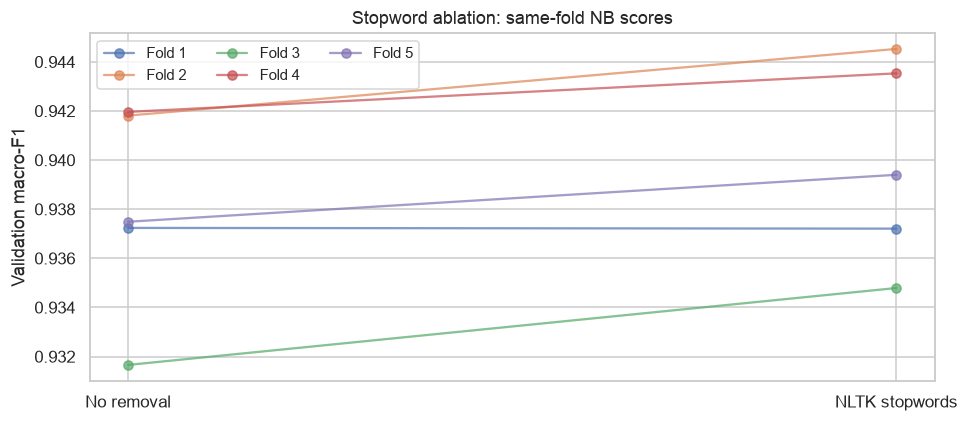

In [8]:
nb_variants={"No removal":base_tokens,"NLTK stopwords":without_stopwords}
nb_records=[];warning_records=[]
with threadpool_limits(limits=2):
    for method,documents in nb_variants.items():
        for fold,(fitting,validation) in enumerate(folds,1):
            record,pipeline,caught=score_fold(documents,y,fitting,validation,family="NB")
            nb_records.append({"method":method,"fold":fold,**record})
            warning_records.extend({"family":"NB","method":method,"fold":fold,**w} for w in caught)
            del pipeline
nb_folds=pd.DataFrame(nb_records)
nb_summary=nb_folds.groupby("method",sort=False).agg(
    mean_F1=("macro_F1","mean"),sample_SD=("macro_F1","std"),mean_accuracy=("accuracy","mean"),
    mean_vocab=("vocabulary","mean"),min_vocab=("vocabulary","min"),max_vocab=("vocabulary","max"))
nb_scores=nb_folds.pivot(index="method",columns="fold",values="macro_F1").reindex(nb_variants)
nb_scores.columns=[f"Fold {i}" for i in nb_scores.columns]
show_table(nb_summary.round(6),"MultinomialNB: macro-F1 mean/sample SD and supporting accuracy")
show_table(nb_scores.round(6),"All five NB macro-F1 scores")
show_table(nb_folds.round(6),"NB fold vocabulary, accuracy and runtime",collapse=True,index=False)
nb_deltas=nb_folds.pivot(index="fold",columns="method",values="macro_F1")
nb_deltas["stopwords_minus_baseline"]=nb_deltas["NLTK stopwords"]-nb_deltas["No removal"]
show_table(nb_deltas.round(6),"Same-fold NB differences",collapse=True)
fig,ax=plt.subplots(figsize=(9,4))
for index,fold in enumerate(range(1,6)):
    values=nb_folds.loc[nb_folds.fold.eq(fold)].set_index("method").loc[list(nb_variants),"macro_F1"]
    ax.plot([0,1],values,marker="o",alpha=.7,label=f"Fold {fold}")
ax.set_xticks([0,1],list(nb_variants));ax.set(ylabel="Validation macro-F1",title="Stopword ablation: same-fold NB scores")
ax.legend(fontsize=10,ncol=3);plt.tight_layout();plt.show()
nb_delta=float(nb_summary.loc["NLTK stopwords","mean_F1"]-nb_summary.loc["No removal","mean_F1"])
display(prose(f"**Observed:** NB mean macro-F1 changes by **{nb_delta:+.5f}** "
              f"({nb_delta*100:+.3f} percentage points); paired fold differences range from "
              f"**{nb_deltas.stopwords_minus_baseline.min():+.5f}** to "
              f"**{nb_deltas.stopwords_minus_baseline.max():+.5f}**. "
              f"The baseline and filtered sample SDs are **{nb_summary.loc['No removal','sample_SD']:.5f}** "
              f"and **{nb_summary.loc['NLTK stopwords','sample_SD']:.5f}**. "
              "Compare this practical change with fold variation; neither a changed mean MI nor smaller "
              "vocabulary guarantees an F1 increase. These five dependent folds do not prove a universal effect."))
nb_positive_folds=int(nb_deltas.stopwords_minus_baseline.gt(0).sum())
display(prose(f"**Cross-metric interpretation:** mean MI {direction}, while NB changes by "
              f"**{nb_delta:+.5f} F1** and improves in **{nb_positive_folds}/5** paired folds. "
              "There is no contradiction: mean univariate presence information and predictions from "
              "smoothed count likelihoods measure different things. Correlated function/template words "
              "are plausible contributors, not an identified causal explanation. The removed word 'about' "
              "has high observed MI in this corpus; removal cannot be described as discarding only uninformative words."))


### B1 — Morphology definitions and unique-type collisions

Keep stopwords in **all four** variants. Transform only **ASCII alphabetic lexical tokens**;
digit-bearing codes, pure numbers, apostrophized tokens and non-ASCII types pass through
unchanged. Alphabetic brands can still be stemmed: the guard is not a brand detector.

- **None:** identity mapping.
- **Porter:** NLTK `PorterStemmer`, `NLTK_EXTENSIONS` mode.
- **Snowball:** `SnowballStemmer("english", ignore_stopwords=False)`.
- **WordNet noun:** `WordNetLemmatizer.lemmatize(token, pos="n")`; a **noun-default baseline**,
  not POS-aware lemmatization of verbs/adjectives. No POS tagger is added. NLTK chooses the
  shortest available noun lemma, which can have surprising forms; see
  [the WordNet lemmatizer definition](https://www.nltk.org/api/nltk.stem.wordnet.html).

Memoize these fixed mappings on observed training types, then apply them to every training
record. A validation-only type can be deterministically transformed, but cannot enter a fold's
vectorizer vocabulary unless present in its fitting data. The mapping uses no class labels,
frequency threshold or fitted corpus statistics. Collisions may be intended inflection/derivation
merges; stems that are not dictionary words are not automatically semantic errors.

In [9]:
porter=PorterStemmer(mode=PorterStemmer.NLTK_EXTENSIONS)
snowball=SnowballStemmer("english",ignore_stopwords=False)
lemmatizer=WordNetLemmatizer()
morph_functions={"None":lambda token:token,"Porter":porter.stem,"Snowball":snowball.stem,
                 "WordNet noun":lambda token:lemmatizer.lemmatize(token,pos="n")}
def eligible_for_morphology(token): return token.isascii() and token.isalpha()
eligible_types=sum(eligible_for_morphology(token) for token in base_vocabulary)
morph_maps={};morph_groups={};morph_variants={};collision_rows=[]
for method,function in morph_functions.items():
    mapping={token:function(token) if eligible_for_morphology(token) else token for token in base_vocabulary}
    assert all(mapping[token]==token for token in base_vocabulary if not eligible_for_morphology(token))
    assert all(isinstance(form,str) and form!="" for form in mapping.values())
    report,groups=collision_summary(mapping)
    collision_rows.append({"method":method,"eligible_ASCII_alpha_types":eligible_types,**report})
    morph_maps[method]=mapping;morph_groups[method]=groups
    morph_variants[method]=base_tokens.map(lambda tokens:[mapping[token] for token in tokens])
    assert all(len(a)==len(b) for a,b in zip(base_tokens,morph_variants[method]))
collision_table=pd.DataFrame(collision_rows).set_index("method")
show_table(collision_table[["V_input_types","U_output_forms","compression_pct","collision_membership_pct"]].rename(
    columns={"V_input_types":"V input","U_output_forms":"U forms","compression_pct":"Compression %",
             "collision_membership_pct":"Collision membership %"}).round(4),
           "Two distinct type-level collision measures")
show_table(collision_table,"Counts, changed types and eligible types",collapse=True)

# Frequent real collision groups, using original training counts only for display ordering.
collision_examples=[]
for method in list(morph_functions)[1:]:
    groups=morph_groups[method]
    common=sorted(((form,words) for form,words in groups.items() if len(words)>=2),
                  key=lambda item:(-sum(base_counter[w] for w in item[1]),item[0]))[:4]
    for form,words in common:
        collision_examples.append({"method":method,"output_form":form,"input_type_count":len(words),
            "real_input_types":", ".join(sorted(words)[:15]),"omitted_input_types":max(0,len(words)-15)})
show_table(pd.DataFrame(collision_examples),"Frequent observed collision groups",index=False)

# Fixed pedagogical pairs are shown only if both actually occur in TRAIN.
pairs=[("book","books","plausible singular/plural merge"),
       ("battery","batteries","plausible singular/plural merge"),
       ("universe","university","different senses: potential overstemming"),
       ("organ","organic","different senses: contextual risk"),
       ("general","generous","different senses: contextual risk"),
       ("us","u","noun-default shortest-lemma caveat")]
pair_rows=[]
for method,mapping in morph_maps.items():
    if method=="None":continue
    for a,b,interpretation in pairs:
        if a in mapping and b in mapping:
            pair_rows.append({"method":method,"real_types":f"{a} / {b}","mapped_forms":f"{mapping[a]} / {mapping[b]}",
                              "merged":mapping[a]==mapping[b],"interpretation":interpretation})
pair_examples=pd.DataFrame(pair_rows)
main_pair_mask=(pair_examples.real_types.eq("book / books")
    | (pair_examples.method.isin(["Porter","Snowball"]) & pair_examples.real_types.eq("universe / university"))
    | (pair_examples.method.eq("WordNet noun") & pair_examples.real_types.eq("us / u")))
show_table(pair_examples.loc[main_pair_mask],"Actual merges: plausible inflections and semantic risks",index=False)
show_table(pair_examples,"All observed inflections and semantic-risk candidates",collapse=True,index=False)
unchanged_examples=[]
for method,mapping in morph_maps.items():
    if method=="None":continue
    words=sorted((w for w in base_vocabulary if mapping[w]==w),key=lambda w:(-base_counter[w],w))[:6]
    unchanged_examples.append({"method":method,"unchanged_real_types":", ".join(words)})
show_table(pd.DataFrame(unchanged_examples),"Frequent unchanged real training types",index=False)
for method in list(morph_functions)[1:]:
    row=collision_table.loc[method]
    display(prose(f"**Observed — {method}:** **{int(row.V_input_types):,} → {int(row.U_output_forms):,}** types/forms; "
                  f"compression **{row.compression_pct:.2f}%**, versus **{row.collision_membership_pct:.2f}%** "
                  "of input types belonging to multi-input groups. These denominators refer to unique types, "
                  "not token occurrences. High collision membership is not itself proof of useful generalization or semantic error."))

,V input,U forms,Compression %,Collision membership %
method,,,,
None,72299,72299,0.0000,0.0000
Porter,72299,57444,20.5466,31.5329
Snowball,72299,57318,20.7209,31.5786
WordNet noun,72299,66900,7.4676,14.8813


,eligible_ASCII_alpha_types,V_input_types,U_output_forms,compression_pct,types_in_collision_groups,collision_membership_pct,multi_input_groups,changed_types
method,,,,,,,,
None,56695,72299,72299,0.000000,0,0.000000,0,0
Porter,56695,72299,57444,20.546619,22798,31.532940,7943,29768
Snowball,56695,72299,57318,20.720895,22831,31.578583,7850,29184
WordNet noun,56695,72299,66900,7.467600,10759,14.881257,5360,6203


method,output_form,input_type_count,real_input_types,omitted_input_types
Porter,and,2,"and, ande",0
Porter,of,2,"of, ofs",0
Porter,in,2,"in, ins",0
Porter,it,2,"it, its",0
Snowball,and,2,"and, ande",0
Snowball,of,2,"of, ofs",0
Snowball,in,2,"in, ins",0
Snowball,it,2,"it, its",0
WordNet noun,a,2,"a, as",0
WordNet noun,in,2,"in, ins",0


method,real_types,mapped_forms,merged,interpretation
Porter,book / books,book / book,True,plausible singular/plural merge
Porter,universe / university,univers / univers,True,different senses: potential overstemming
Snowball,book / books,book / book,True,plausible singular/plural merge
Snowball,universe / university,univers / univers,True,different senses: potential overstemming
WordNet noun,book / books,book / book,True,plausible singular/plural merge
WordNet noun,us / u,u / u,True,noun-default shortest-lemma caveat


method,real_types,mapped_forms,merged,interpretation
Porter,book / books,book / book,True,plausible singular/plural merge
Porter,battery / batteries,batteri / batteri,True,plausible singular/plural merge
Porter,universe / university,univers / univers,True,different senses: potential overstemming
Porter,organ / organic,organ / organ,True,different senses: contextual risk
Porter,general / generous,gener / gener,True,different senses: contextual risk
Porter,us / u,us / u,False,noun-default shortest-lemma caveat
Snowball,book / books,book / book,True,plausible singular/plural merge
Snowball,battery / batteries,batteri / batteri,True,plausible singular/plural merge
Snowball,universe / university,univers / univers,True,different senses: potential overstemming
Snowball,organ / organic,organ / organ,True,different senses: contextual risk


method,unchanged_real_types
Porter,"the, and, of, to, a, for"
Snowball,"the, and, of, to, a, for"
WordNet noun,"the, and, of, to, a, for"


### B2 — Fixed TF-IDF + Logistic Regression five-fold CV

Use unigram TF-IDF on pretokenized lists: `min_df=2`, `max_df=1.0`, `max_features=30000`,
`sublinear_tf=True`, smoothed training-only IDF, L2 row normalization, float64. The callable
analyzer returns the token list unchanged; it does not run another tokenizer, stopword filter
or n-gram expansion. All four methods use this identical configuration.

The classifier minimizes multinomial cross-entropy with L2 regularization: `C=1`,
`l1_ratio=0`, `solver="lbfgs"`, `max_iter=1000`, `tol=1e-4`, seed 42. No grid search or
performance-targeted pilot result is used. Limit BLAS to two threads for the CPU run.
Record actual warnings and iteration counts; reaching the iteration budget would require
an explicitly reported convergence remedy, not silent suppression. These are controlled
morphology ablations, not Stage 04 representation benchmarks.

,mean_F1,sample_SD,mean_accuracy,mean_vocab
method,,,,
None,0.947950,0.003482,0.948290,30000.0
Porter,0.948559,0.004027,0.949056,23400.2
Snowball,0.948589,0.003684,0.949146,23306.6
WordNet noun,0.948760,0.003929,0.949236,28693.0


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5
method,,,,,
None,0.951788,0.949693,0.942986,0.949360,0.945925
Porter,0.951498,0.951910,0.942925,0.950786,0.945678
Snowball,0.950965,0.951902,0.943280,0.950565,0.946230
WordNet noun,0.952344,0.951921,0.942651,0.949272,0.947611


,min_vocab,max_vocab,mean_seconds,max_iterations,convergence_warnings
method,,,,,
None,30000,30000,1.640,81,0
Porter,23275,23505,1.406,72,0
Snowball,23185,23424,1.328,70,0
WordNet noun,28567,28818,1.526,70,0


method,fold,macro_F1,accuracy,vocabulary,seconds,warnings,convergence_warnings,iterations
None,1,0.951788,0.952263,30000,1.563344,0,0,67
None,2,0.949693,0.949775,30000,1.659166,0,0,69
None,3,0.942986,0.943694,30000,1.537931,0,0,62
None,4,0.949360,0.949775,30000,1.847259,0,0,81
None,5,0.945925,0.945946,30000,1.594125,0,0,69
Porter,1,0.951498,0.952263,23366,1.480351,0,0,71
Porter,2,0.951910,0.952027,23496,1.333505,0,0,59
Porter,3,0.942925,0.943694,23359,1.460764,0,0,72
Porter,4,0.950786,0.951351,23505,1.400035,0,0,67
Porter,5,0.945678,0.945946,23275,1.353592,0,0,63


family,method,fold,category,message


,Compression %,Collision %,Forms,CV vocab,Mean F1,SD
method,,,,,,
None,0.00000,0.00000,72299,30000.0,0.94795,0.00348
Porter,20.54662,31.53294,57444,23400.2,0.94856,0.00403
Snowball,20.72090,31.57858,57318,23306.6,0.94859,0.00368
WordNet noun,7.46760,14.88126,66900,28693.0,0.94876,0.00393


method,Porter,Snowball,WordNet noun
fold,,,
1,-0.000290,-0.000823,0.000556
2,0.002217,0.002209,0.002227
3,-0.000061,0.000294,-0.000335
4,0.001426,0.001206,-0.000088
5,-0.000247,0.000305,0.001686


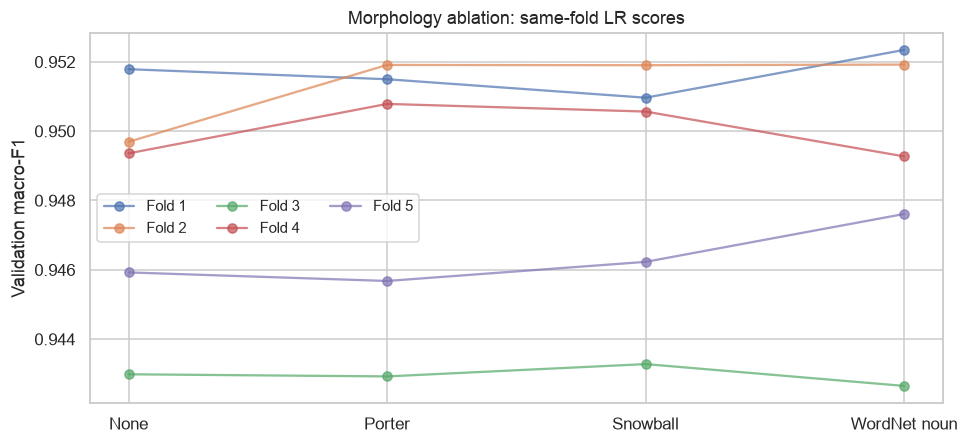

In [10]:
lr_records=[]
with threadpool_limits(limits=2):
    for method,documents in morph_variants.items():
        for fold,(fitting,validation) in enumerate(folds,1):
            record,pipeline,caught=score_fold(documents,y,fitting,validation,family="LR")
            lr_records.append({"method":method,"fold":fold,**record})
            warning_records.extend({"family":"LR","method":method,"fold":fold,**w} for w in caught)
            del pipeline
lr_folds=pd.DataFrame(lr_records)
lr_summary=lr_folds.groupby("method",sort=False).agg(
    mean_F1=("macro_F1","mean"),sample_SD=("macro_F1","std"),mean_accuracy=("accuracy","mean"),
    mean_vocab=("vocabulary","mean"),min_vocab=("vocabulary","min"),max_vocab=("vocabulary","max"),
    mean_seconds=("seconds","mean"),max_iterations=("iterations","max"),
    convergence_warnings=("convergence_warnings","sum"))
lr_scores=lr_folds.pivot(index="method",columns="fold",values="macro_F1").reindex(morph_variants)
lr_scores.columns=[f"Fold {i}" for i in lr_scores.columns]
show_table(lr_summary[["mean_F1","sample_SD","mean_accuracy","mean_vocab"]].round(6),
           "Morphology LR CV: mean/sample SD and supporting accuracy")
show_table(lr_scores.round(6),"All five LR macro-F1 scores")
show_table(lr_summary[["min_vocab","max_vocab","mean_seconds","max_iterations","convergence_warnings"]].round(3),
           "Fold vocabulary range, runtime and actual convergence")
show_table(lr_folds.round(6),"All LR fold records",collapse=True,index=False)
warning_table=pd.DataFrame(warning_records,columns=["family","method","fold","category","message"])
show_table(warning_table,"Actual warning log (empty means no warnings)",collapse=True,index=False)
combined=collision_table[["compression_pct","collision_membership_pct","U_output_forms"]].join(
    lr_summary[["mean_vocab","mean_F1","sample_SD"]])
show_table(combined.rename(columns={"compression_pct":"Compression %","collision_membership_pct":"Collision %",
    "U_output_forms":"Forms","mean_vocab":"CV vocab","mean_F1":"Mean F1","sample_SD":"SD"}).round(5),
    "Method → type compression/collision → fitted vocabulary → LR CV")
paired_lr=lr_folds.pivot(index="fold",columns="method",values="macro_F1")
paired_lr_deltas=paired_lr.subtract(paired_lr["None"],axis=0).drop(columns="None")
show_table(paired_lr_deltas.round(6),"LR same-fold differences from no morphology",collapse=True)
fig,ax=plt.subplots(figsize=(9,4.2))
for fold in range(1,6):
    values=lr_folds.loc[lr_folds.fold.eq(fold)].set_index("method").loc[list(morph_variants),"macro_F1"]
    ax.plot(range(4),values,marker="o",alpha=.7,label=f"Fold {fold}")
ax.set_xticks(range(4),list(morph_variants));ax.set(ylabel="Validation macro-F1",title="Morphology ablation: same-fold LR scores")
ax.legend(fontsize=10,ncol=3);plt.tight_layout();plt.show()
best_lr=lr_summary.mean_F1.idxmax()
best_lr_delta=float(lr_summary.loc[best_lr,"mean_F1"]-lr_summary.loc["None","mean_F1"])
display(prose(f"**Observed:** highest mean LR macro-F1 is **{best_lr}** "
              f"(**{lr_summary.loc[best_lr,'mean_F1']:.5f}**), a difference of **{best_lr_delta:+.5f}** "
              f"from no morphology. Baseline SD = **{lr_summary.loc['None','sample_SD']:.5f}**; "
              f"highest-mean method SD = **{lr_summary.loc[best_lr,'sample_SD']:.5f}**. "
              f"Actual convergence warnings across the 20 LR fits: **{int(lr_folds.convergence_warnings.sum())}**; "
              f"largest iteration count: **{int(lr_folds.iterations.max())}**. "
              "Compression and predictive improvement are different outcomes; a small mean difference "
              "in shared folds does not certify a reliable winner. No internal-assessment outcome is consulted."))

## Discussion

Stopwords remove a small set of types with potentially many occurrences. Their binary
presence can still carry class information, including style/template signals; empirical MI
is not a causal claim that a word describes product semantics. A changed mean MI after
filtering reflects changing the averaging vocabulary. The common-type check separates that
mechanism from any change in the remaining word events. NB CV asks a separate prediction
question under its count model and independence assumptions.

Here, `about`, `he` and `his` are informative stopwords in the empirical tables, plausibly
reflecting author biographies and product-description styles. Their removal lowers the mean
MI, while NB shows a small mean gain: the averaging-set question and the model-prediction
question are different. The paired fold differences include a non-improving fold, so this
is not an unconditional recommendation to remove stopwords.

Morphology deliberately merges types. The two collision rates quantify different aspects:
compression counts redundant forms; membership counts every type in a multi-input group.
Some merges are useful inflections, others cross distinct senses or alter brands. An
unrecognizable stem is not automatically a semantic error; WordNet's readable noun lemma is
not automatically a correct POS analysis either. Numeric/code guards preserve digit-bearing
pieces, while the shared lexical definition still fragments punctuation-separated IDs.

The examples `universe`/`university` collapsing under both stemmers and `us`/`u` collapsing
under noun-default WordNet demonstrate distinct risks. Intended `book`/`books` merges coexist
with them. The 30,000-feature TF-IDF cap binds the no-morphology reference; compression is
measured on all input types, while fitted feature sizes also depend on fold-local `min_df`
and the cap. Thus full-type compression and CV vocabulary reduction are not identical measures.

All six configurations share fixed population and folds. Supervised descriptive MI uses
TRAIN only and never selects features for CV. Precomputed stateless mappings do not supply
validation vocabulary/IDF; each fitted pipeline learns these inside its fitting partition.
Exact normalized grouping handles the observed duplicates, not all product families. Full-file
EDA exposure and remaining related products limit generalization claims. The reported SDs
and paired differences describe this fixed CV, not independent uncertainty intervals.

The evidence table below answers the stopword/MI/NB and morphology/LR questions without
forcing a winner. Stage 04 should retain controlled baselines and declare any later
training-CV selection before evaluating the internal post-EDA assessment.

In [11]:
decision_table=pd.DataFrame([
 {"Decision":"Keep stopword removal as an explicit ablation",
  "Evidence":f"V {len(base_counter):,} → {len(retained_counter):,}; removed {removed_occurrences:,} occurrences; NB ΔF1={nb_delta:+.5f}",
  "Limitation":"Smaller vocabulary/sequence length does not ensure higher predictive performance; negations and style words may carry signal",
  "Use in Stage 04":"Keep no-removal reference and fixed NLTK list; do not infer a universal stopword winner"},
 {"Decision":"Interpret MI as wordwise presence diagnostics",
  "Evidence":f"Mean baseline/remaining/removed={mi_values.mean():.8f}/{remaining_mi.mean():.8f}/{mi_values[~retained_mask].mean():.8f} nats; common-word max change={common_max_change:.2g}",
  "Limitation":"Means use different type sets; rare-type plug-in bias and dependent words prevent joint-information interpretation",
  "Use in Stage 04":"Any MI-based feature selection must be fitted within training folds, not from this descriptive full-TRAIN table"},
 {"Decision":"Compare morphology trade-offs rather than collision alone",
  "Evidence":"; ".join(f"{method}: compression {collision_table.loc[method,'compression_pct']:.2f}%, membership {collision_table.loc[method,'collision_membership_pct']:.2f}%, LR F1 {lr_summary.loc[method,'mean_F1']:.5f}" for method in list(morph_functions)[1:]),
  "Limitation":"Inflections and cross-sense/brand conflations coexist; noun-default WordNet is not full POS-aware lemmatization",
  "Use in Stage 04":"Retain raw/base tokens and no-morphology reference; validate information loss and representation effects"},
 {"Decision":"Do not claim a certain morphology winner",
  "Evidence":f"Highest mean={best_lr}; Δ versus None={best_lr_delta:+.5f}; baseline SD={lr_summary.loc['None','sample_SD']:.5f}",
  "Limitation":"Five folds share fitting data and close scores do not prove an improvement; no external evaluation",
  "Use in Stage 04":"Use training CV only for any declared selection; leave assessment classification for the later stage"},
 {"Decision":"Keep numbers and the Stage 02 baseline fixed",
  "Evidence":f"{len(base_counter):,} base types; non-ASCII/nonalphabetic/digit-bearing types bypass morphology; known @home deletion risk retained",
  "Limitation":"Preserving digit-bearing pieces does not repair mention loss or punctuation-fragmented IDs",
  "Use in Stage 04":"Compare representations on a documented fixed input; new normalization policies require a separate controlled question"},
 {"Decision":"Reuse the normalized-base group folds",
  "Evidence":f"{int(group_audit.duplicate_groups)} duplicate groups; five folds with zero normalized-group overlap; no assessment text used",
  "Limitation":"Group equality does not capture all near-duplicate/product families; EDA exposed the whole source",
  "Use in Stage 04":"Recreate this grouping recipe and report remaining dependence; do not silently regenerate method-specific folds"},
])
show_table(decision_table,index=False)

Decision,Evidence,Limitation,Use in Stage 04
Keep stopword removal as an explicit ablation,"V 72,299 → 72,119; removed 820,416 occurrences; NB ΔF1=+0.00186",Smaller vocabulary/sequence length does not ensure higher predictive performance; negations and style words may carry signal,Keep no-removal reference and fixed NLTK list; do not infer a universal stopword winner
Interpret MI as wordwise presence diagnostics,Mean baseline/remaining/removed=0.00041228/0.00039878/0.00582292 nats; common-word max change=0,Means use different type sets; rare-type plug-in bias and dependent words prevent joint-information interpretation,"Any MI-based feature selection must be fitted within training folds, not from this descriptive full-TRAIN table"
Compare morphology trade-offs rather than collision alone,"Porter: compression 20.55%, membership 31.53%, LR F1 0.94856; Snowball: compression 20.72%, membership 31.58%, LR F1 0.94859; WordNet noun: compression 7.47%, membership 14.88%, LR F1 0.94876",Inflections and cross-sense/brand conflations coexist; noun-default WordNet is not full POS-aware lemmatization,Retain raw/base tokens and no-morphology reference; validate information loss and representation effects
Do not claim a certain morphology winner,Highest mean=WordNet noun; Δ versus None=+0.00081; baseline SD=0.00348,Five folds share fitting data and close scores do not prove an improvement; no external evaluation,Use training CV only for any declared selection; leave assessment classification for the later stage
Keep numbers and the Stage 02 baseline fixed,"72,299 base types; non-ASCII/nonalphabetic/digit-bearing types bypass morphology; known @home deletion risk retained",Preserving digit-bearing pieces does not repair mention loss or punctuation-fragmented IDs,Compare representations on a documented fixed input; new normalization policies require a separate controlled question
Reuse the normalized-base group folds,11 duplicate groups; five folds with zero normalized-group overlap; no assessment text used,Group equality does not capture all near-duplicate/product families; EDA exposed the whole source,Recreate this grouping recipe and report remaining dependence; do not silently regenerate method-specific folds


## Conclusion

Stage 03 supplies the required stopword vocabulary/MI/Naive Bayes ablation and four-way
morphology collision/Logistic Regression CV comparison, with train-only statistics, the same
five grouped folds and fold-local learned representations. Real counts, all five scores,
sample SDs, warnings and examples remain saved in this notebook. Shared normalization was
extracted without changing Stage 02's behavior; no policy is selected from the internal
assessment, and no classifier is evaluated there.

**Stage 04 — Representations** is still pending: compare the required BoW/TF-IDF n-grams,
Word2Vec and semantic representations, their dimensions/sparsity/similarity/visualization and
controlled downstream behavior. This chapter's Count/TF-IDF use is limited to the mandated
ablations and does not complete those benchmarks. See the [Part B roadmap](index.md).
Part B and the whole assignment remain incomplete.

In [12]:
raw_sha256_after=hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
pd.testing.assert_frame_equal(raw,raw_snapshot)
assert raw_sha256_after==raw_sha256_before
assert len(nb_folds)==10 and len(lr_folds)==20
assert np.all(validation_use==1)
assert all(len(tokens)==len(train) for tokens in [base_tokens,without_stopwords,*morph_variants.values()])
assert set(train.row_id).isdisjoint(assessment_ids)
show_table(pd.Series({"before":raw_sha256_before,"after":raw_sha256_after},name="Raw SHA-256").to_frame())
print("Read-only raw integrity, fixed row populations, outer membership and grouped CV boundaries verified.")
print("10 NB + 20 LR fold fits saved; no classifier assessment, corpus export or mandatory cache created.")

,Raw SHA-256
before,1d44be1780bc9558f40ab4cee5b32051ddfe90647cd525b9652b47cdb233593f
after,1d44be1780bc9558f40ab4cee5b32051ddfe90647cd525b9652b47cdb233593f


Read-only raw integrity, fixed row populations, outer membership and grouped CV boundaries verified.
10 NB + 20 LR fold fits saved; no classifier assessment, corpus export or mandatory cache created.
